# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
from aitlas.datasets import RSICB256Dataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/RSI-CB256/",
    "csv_file": "./data/RSI-CB256/train.csv",
    "batch_size": 128,
    "shuffle": True,
    "num_workers": 4,
}
dataset = RSICB256Dataset(dataset_config)

## Show images from the dataset

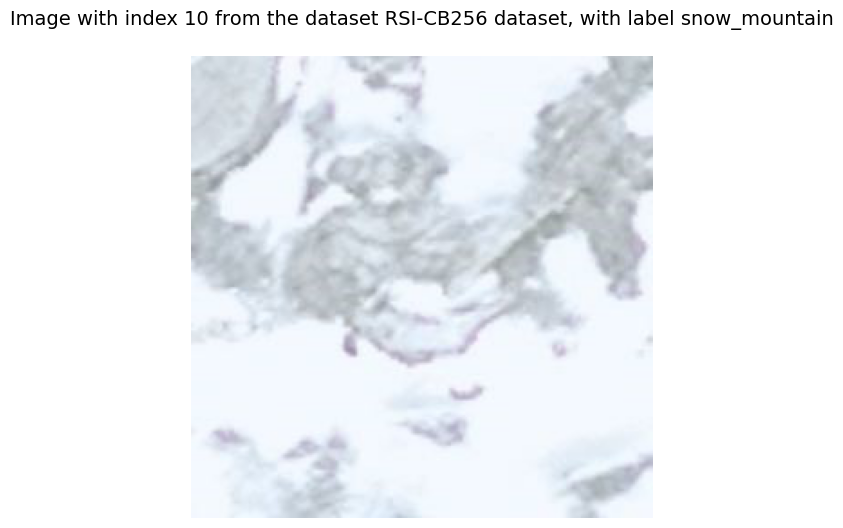

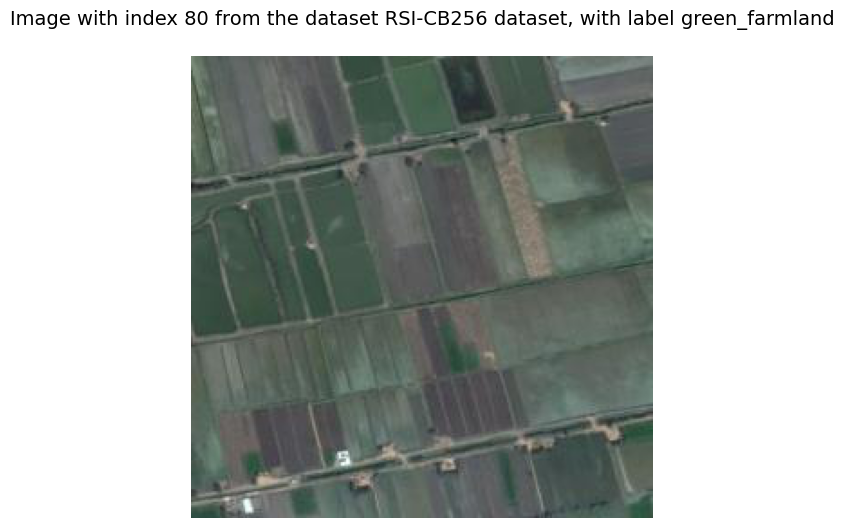

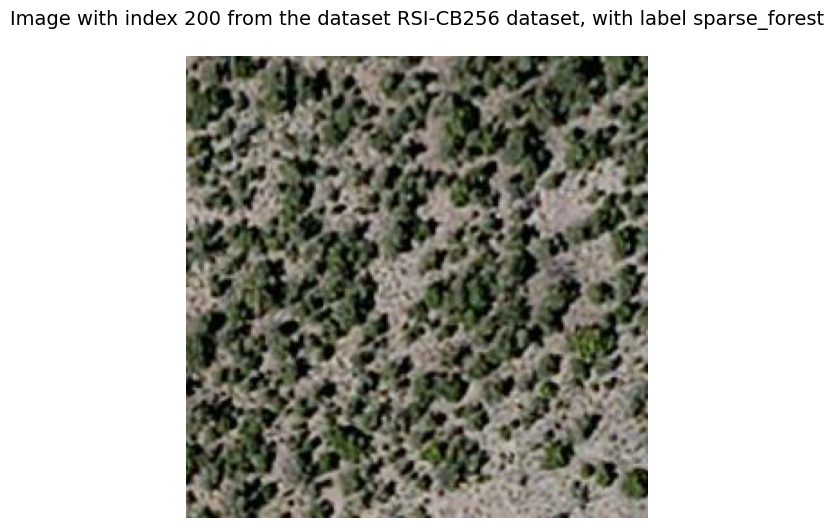

In [5]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(80)
fig3 = dataset.show_image(200)

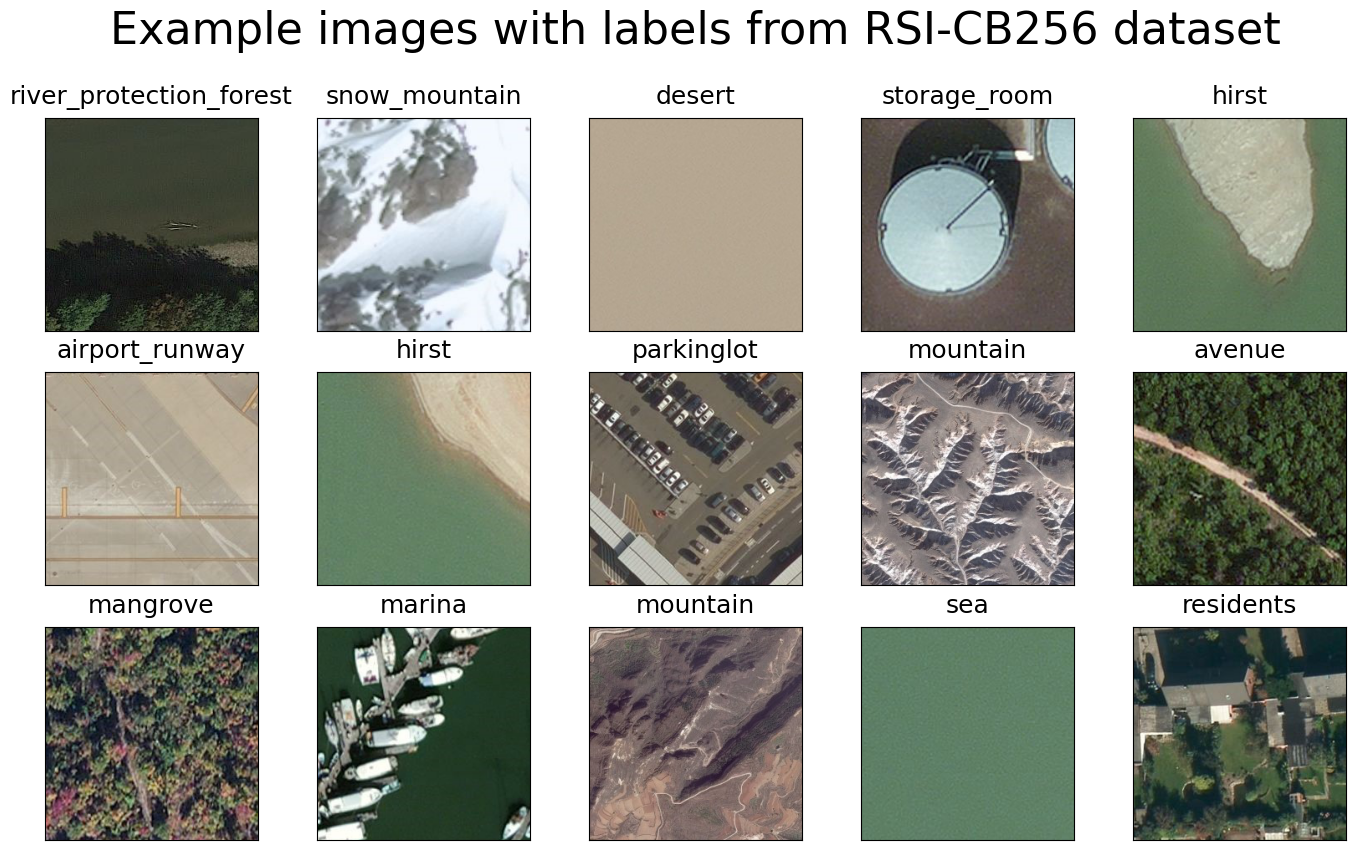

In [32]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [33]:
dataset.show_samples()

,File name,Label
0,river/river(510).tif,water area
1,shrubwood/shrubwood(704).tif,woodland
2,desert/desert(912).tif,other land
3,dam/dam(234).tif,water area
4,mangrove/mangrove(324).tif,woodland
5,airport_runway/airport_runway(94).tif,transportation
6,sparse_forest/sparse_forest(548).tif,woodland
7,parkinglot/parkinglot(79).tif,transportation
8,sea/sea(576).tif,water area
9,desert/desert(286).tif,other land


In [34]:
dataset.data_distribution_table()

,Label,Count
0,airplane,283
1,airport_runway,547
2,artificial_grassland,233
3,avenue,438
4,bare_land,678
5,bridge,376
6,city_building,807
7,coastline,362
8,container,536
9,crossroads,443


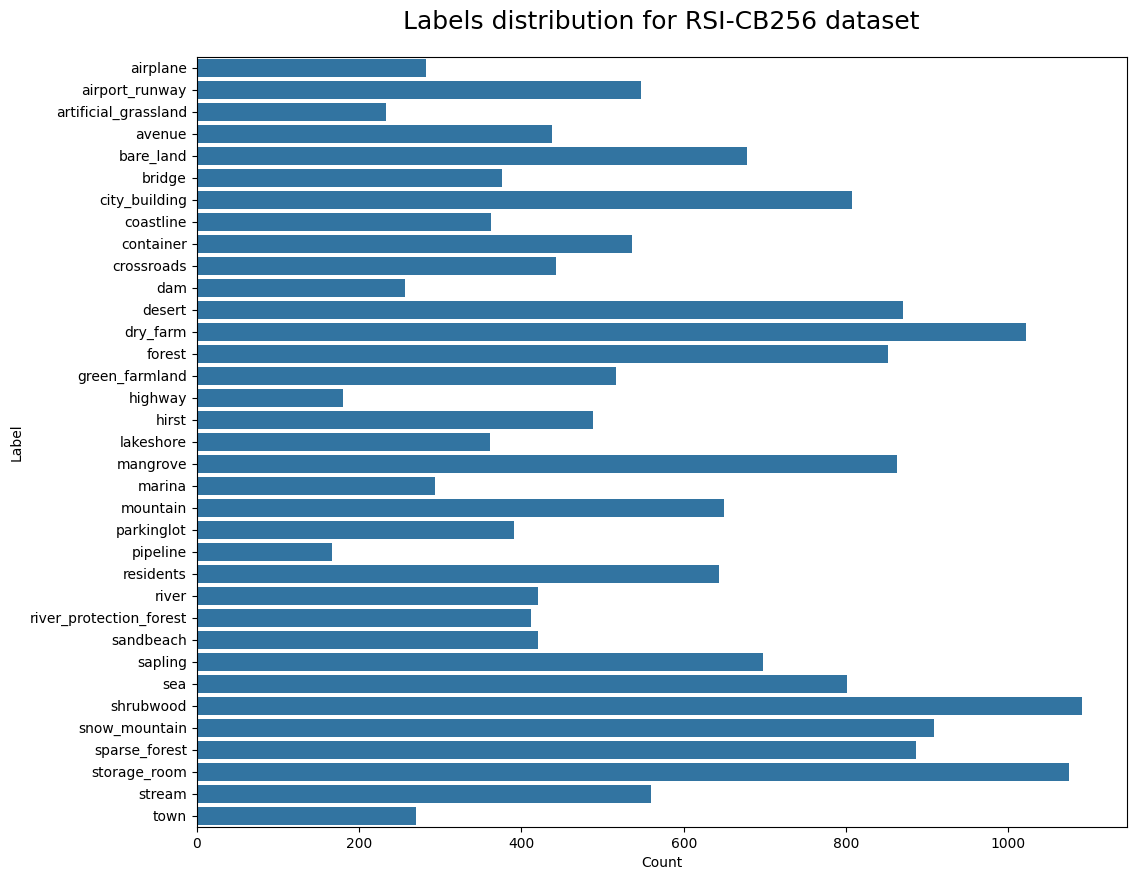

In [35]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/RSI-CB256/",
    "csv_file": "./data/RSI-CB256/train.csv",
}

train_dataset = RSICB256Dataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/RSI-CB256/",
    "csv_file": "./data/RSI-CB256/val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = RSICB256Dataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(19799, 2474)

## Setup and create the model for training

In [ ]:
epochs = 20
model_directory = "./data/experiments/RSI-CB256/"
model_config = {
    "num_classes": 35, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-05-14 07:09:00,849 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-05-14 07:09:01,033 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [8]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-05-14 07:09:01,805 INFO Starting training.
training: 100%|██████████| 619/619 [05:40<00:00,  1.82it/s]
2025-05-14 07:14:42,359 INFO epoch: 1, time: 340, loss:  0.30351
testing on train set: 100%|██████████| 619/619 [01:58<00:00,  5.21it/s]
2025-05-14 07:16:43,579 INFO Accuracy:0.9629779281781908, Precision Micro:0.9629779281781908, Precision Macro:0.9602027591509785, Precision Weighted:0.9661298592614234, Precision per Class:[1.         0.92346939 0.9893617  0.97641509 0.91613924 0.89268293
 0.98974359 0.90025575 1.         0.98550725 1.         0.91847826
 1.         1.         0.99215686 0.97109827 0.95107632 1.
 1.         0.97674419 0.9982906  0.89678899 0.95977011 0.96246246
 0.72841727 0.96244131 0.81584582 0.98019802 0.97622028 0.99444958
 0.96186441 1.         1.         0.99820789 0.98901099], Recall Micro:0.9629779281781908, Recall Macro:0.9569510066921199, Recall Weighted:0.9629779281781908, Recall per Class:[0.97879859 0.99268739 0.79828326 0.94520548 0.8539823  0.9734

0.003268885670409169

## Test the model

In [ ]:

test_dataset_config = {
    "batch_size": 16,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/RSI-CB256/",
    "csv_file": "./data/RSI-CB256/test.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = RSICB256Dataset(test_dataset_config)
model_path = "./data/experiments/RSI-CB256/checkpoint.pth.tar"
model.metrics = ["accuracy", "precision", "recall", "f1_score"]
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2025-05-14 09:48:43,378 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/RSI-CB256/checkpoint.pth.tar
2025-05-14 09:48:44,233 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/RSI-CB256/checkpoint.pth.tar at epoch 21
testing on test set: 100%|██████████| 155/155 [00:18<00:00,  8.30it/s]


[{'Accuracy': 0.9951495553759094},
 {'Precision Micro': 0.9951495553759094,
  'Precision Macro': 0.9950805089435703,
  'Precision Weighted': 0.9952080501358547,
  'Precision per Class': array([0.96969697, 1.        , 1.        , 1.        , 0.9787234 ,
         1.        , 1.        , 1.        , 1.        , 1.        ,
         0.97058824, 0.96363636, 1.        , 1.        , 1.        ,
         1.        , 1.        , 1.        , 1.        , 1.        ,
         0.9893617 , 1.        , 1.        , 1.        , 0.96428571,
         1.        , 1.        , 1.        , 1.        , 1.        ,
         1.        , 1.        , 0.99152542, 1.        , 1.        ])},
 {'Recall Micro': 0.9951495553759094,
  'Recall Macro': 0.9940713387141958,
  'Recall Weighted': 0.9951495553759094,
  'Recall per Class': array([1.        , 1.        , 0.96153846, 1.        , 0.95833333,
         0.95238095, 1.        , 0.97916667, 1.        , 1.        ,
         1.        , 0.98148148, 1.        , 1.        

## Predictions

2025-05-14 09:50:30,777 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/RSI-CB256/checkpoint.pth.tar
2025-05-14 09:50:31,457 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/RSI-CB256/checkpoint.pth.tar at epoch 21


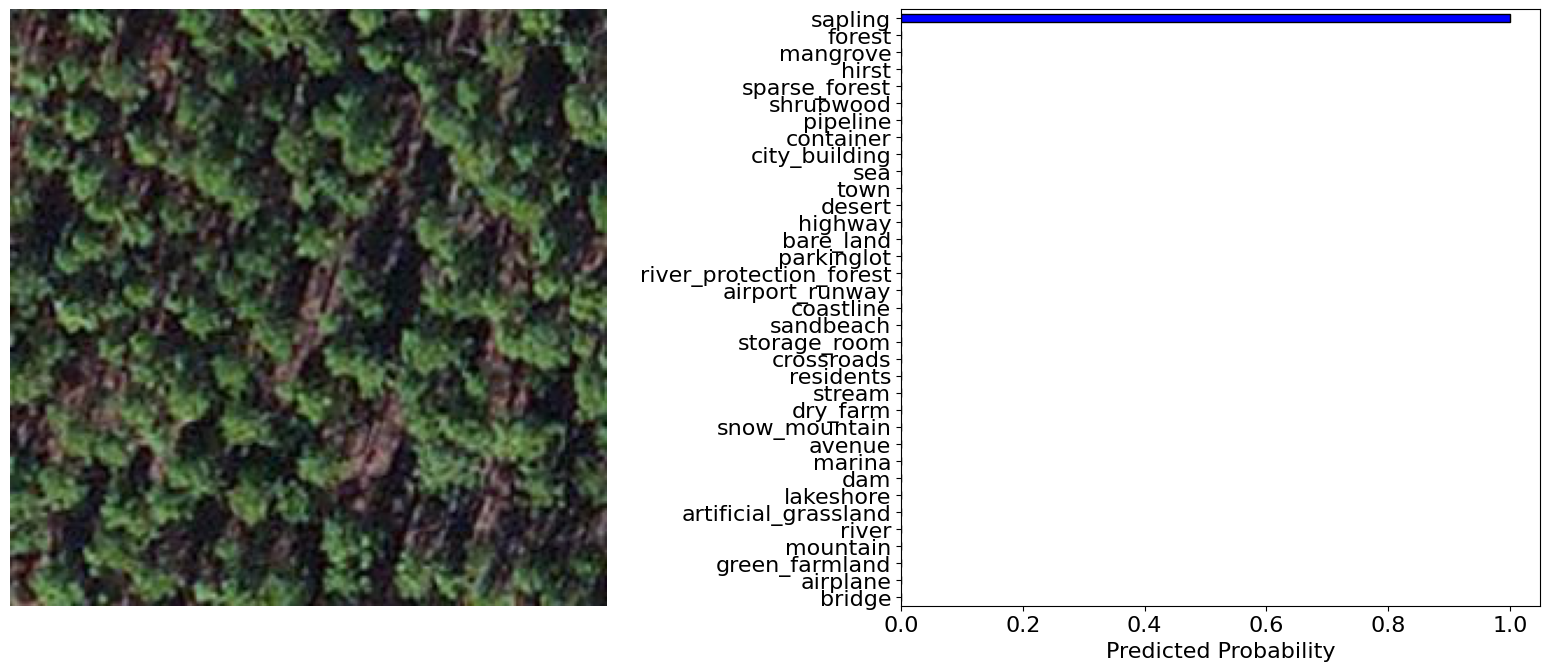

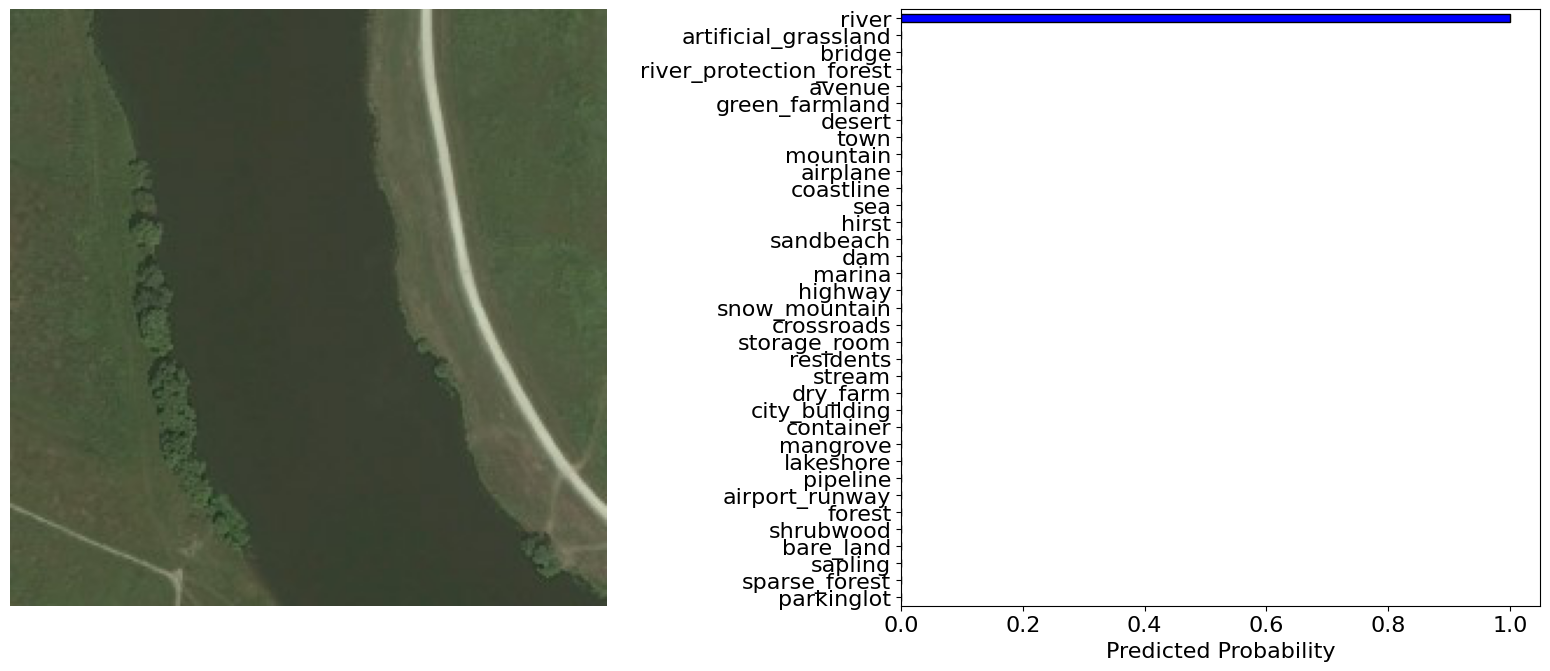

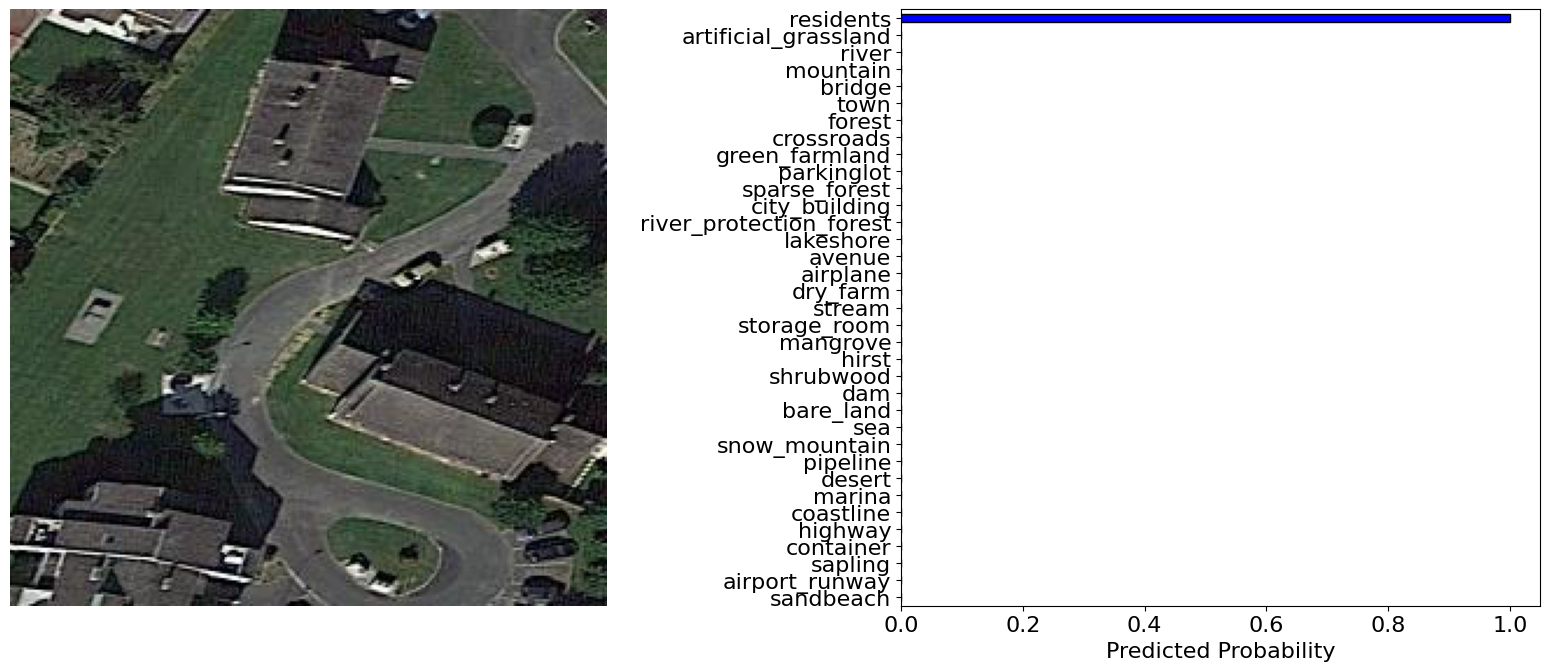

In [ ]:
labels = ["airplane","airport_runway","artificial_grassland","avenue","bare_land","bridge","city_building",
          "coastline","container","crossroads","dam","desert","dry_farm","forest","green_farmland","highway",
          "hirst","lakeshore","mangrove","marina","mountain","parkinglot","pipeline","residents","river",
          "river_protection_forest","sandbeach","sapling","sea","shrubwood","snow_mountain","sparse_forest",
          "storage_room","stream","town"]
transform = ResizeCenterCropToTensor()

model_path = "./data/experiments/RSI-CB256/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('./data/RSI-CB256/woodland/sapling/sapling(803).tif')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/RSI-CB256/water area/river/river(195).tif')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/RSI-CB256/construction land/residents/residents(136).tif')
fig = model.predict_image(image, labels, transform)